# Detekcja uszkodzeń konstrukcji budowlanych: 3 architektury × 2 konfiguracje

**Przedmiot:** Przetwarzanie i analiza cyfrowych danych przestrzennych i budowlanych metodami AI (2026/2027)

**Zbiór danych:** SHM Dataset v4 (Roboflow Universe, workspace `shm-agftj`, projekt `shm-bafca`, wersja 4), pęknięcia betonu.
Sprawdź licencję na stronie zbioru danych i podaj ją w prezentacji.

**Plan: 6 wymaganych treningów**

| | Konfiguracja 1 (wspólna baza) | Konfiguracja 2 (jedna zmiana) |
|---|---|---|
| Architektura A | Wagi wstępnie wytrenowane na COCO | trening od podstaw |
| Architektura B | Wagi wstępnie wytrenowane na COCO | trening od podstaw |
| Architektura C | Wagi wstępnie wytrenowane na COCO | trening od podstaw |

Jedyną różnicą między konfiguracją 1 i 2 są **wagi wstępnie wytrenowane vs trening od podstaw** (taka sama liczba epok).
Pozostałe ustawienia są identyczne we wszystkich przebiegach: seed, podział danych, podzbiór, rozmiar wejściowy, liczba epok, augmentacja i metryki.

**Jak uruchomić:** Środowisko -> Zmień typ środowiska -> GPU (T4). Uzupełnij komórkę ustawień, a następnie uruchom wszystkie komórki.
Każdy ukończony przebieg jest zapisany w Google Drive, więc po rozłączeniu można ponownie uruchomić cały notebook: zakończone przebiegi zostaną pominięte.

In [4]:
# Wersja PyTorch z obsługą GPU musi być zainstalowana WCZEŚNIEJ (patrz README, sekcja 'GPU setup'); tutaj dodajemy tylko ultralytics
#%pip install -q ultralytics
#%pip install ultralytics jupyter ipykernel pandas matplotlib pyyaml
#%pip uninstall -y torch torchvision
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu126

Looking in indexes: https://download.pytorch.org/whl/cu126
  Using cached torchvision-0.29.1%2Bcu126-cp314-cp314-win_amd64.whl.metadata (5.8 kB)
   ---------------------------------------- 0.0/2.6 GB ? eta -:--:--
   ---------------------------------------- 0.0/2.6 GB 9.3 MB/s eta 0:04:42
   ---------------------------------------- 0.0/2.6 GB 11.7 MB/s eta 0:03:44
   ---------------------------------------- 0.0/2.6 GB 11.8 MB/s eta 0:03:43
   ---------------------------------------- 0.0/2.6 GB 11.8 MB/s eta 0:03:42
   ---------------------------------------- 0.0/2.6 GB 11.8 MB/s eta 0:03:42
   ---------------------------------------- 0.0/2.6 GB 11.8 MB/s eta 0:03:41
   ---------------------------------------- 0.0/2.6 GB 11.8 MB/s eta 0:03:41
   ---------------------------------------- 0.0/2.6 GB 11.8 MB/s eta 0:03:41
   ---------------------------------------- 0.0/2.6 GB 11.8 MB/s eta 0:03:41
   ---------------------------------------- 0.0/2.6 GB 11.8 MB/s eta 0:03:40
   --------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import os, gc, json, time, shutil, random, zipfile
from collections import Counter
from pathlib import Path

import cv2, yaml, torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ===================== USTAWIENIA =====================
SEED = 42

DATA_SOURCE = "coco"             # "coco" = folder z train/valid/test, każdy z _annotations.coco.json (konwersja odbywa się automatycznie)
                                  # "yolo" = folder z gotowymi etykietami YOLO i data.yaml, "roboflow" = pobranie przez API
COCO_ROOT = r"G:\Studia\Przetwarzanie i analiza cyfrowych danych przestrzennych i budowlanych metodami sztucznej inteligencji\Projekt 4\dane"   # <- ZMIANA: folder zawierający podfoldery train, valid i test
LOCAL_DATA = r"C:\path\to\shm_v4_yolo"   # tylko dla DATA_SOURCE = "yolo"
ROBOFLOW_API_KEY = ""             # tylko dla DATA_SOURCE = "roboflow"

# Budżet obliczeniowy (poniższa komórka szacuje całkowity czas; zmniejsz te wartości, jeśli trening jest zbyt długi)
N_TRAIN, N_VAL, N_TEST = 2000, 400, 500   # liczba obrazów używana z każdego podzbioru
IMGSZ  = 512
EPOCHS = 15
BATCH  = 8                         # RTX 2060 ma 6 GB: przy braku pamięci dla RT-DETR użyj 4 (dla WSZYSTKICH modeli, aby zachować porównywalność)
WORKERS = 11 if os.name == 'nt' else 2   # procesy ładowania danych (0 to bezpieczny wybór dla Windows)
REQUIRE_GPU = True                # natychmiastowe zatrzymanie, jeśli CUDA jest niedostępne, zamiast wielogodzinnego treningu na CPU
DEDUP_TRAIN = True                # Roboflow zapisuje 3 augmentowane kopie każdego obrazu źródłowego w train: zachowaj po jednej kopii źródłowej

USE_DRIVE = False                 # Tylko Colab: zapisuj wyniki w Google Drive
# ====================================================

def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

seed_all()
print("torch", torch.__version__, "| cuda:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Tylko CPU (trening będzie bardzo wolny)")
if REQUIRE_GPU and not torch.cuda.is_available():
    raise SystemExit("CUDA jest niedostępne: PyTorch został zainstalowany bez obsługi GPU. Patrz README, sekcja 'GPU setup'.")

torch 2.14.1+cu126 | cuda: True | NVIDIA GeForce RTX 2060


In [2]:
IN_COLAB = Path("/content").exists()
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS = Path("/content/drive/MyDrive/shm_crack_results")
else:
    RESULTS = Path("results")
WORK = Path("/content/work") if IN_COLAB else Path("work")
LOCAL_RUNS = WORK / "runs"
for d in (RESULTS / "runs", RESULTS / "figures", WORK, LOCAL_RUNS):
    d.mkdir(parents=True, exist_ok=True)
print("results ->", RESULTS.resolve())

results -> G:\Studia\Przetwarzanie i analiza cyfrowych danych przestrzennych i budowlanych metodami sztucznej inteligencji\Projekt 4\results


## 1. Zbiór danych

In [3]:
def coco_to_yolo(src_root, out_root):
    """Eksport Roboflow COCO (train/valid/test + _annotations.coco.json) -> etykiety YOLO txt + data.yaml.
    Ramki są używane do detekcji; jeśli większość annotacji zawiera wielokąty, zapisane zostają etykiety wielokątów (segmentacja)."""
    src_root, out_root = Path(src_root), Path(out_root)
    if out_root.exists(): shutil.rmtree(out_root)
    data = {}
    for sp, cands in {"train": ["train"], "valid": ["valid", "val"], "test": ["test"]}.items():
        d = next((src_root / c for c in cands if (src_root / c / "_annotations.coco.json").exists()), None)
        if d is None: raise FileNotFoundError(f"Brak folderu {cands} z plikiem _annotations.coco.json w {src_root}")
        data[sp] = (d, json.load(open(d / "_annotations.coco.json", encoding="utf-8")))
    used = sorted({a["category_id"] for _, js in data.values() for a in js["annotations"]})   # pomija sztuczną nadrzędną kategorię Roboflow
    cat_name = {c["id"]: c["name"] for _, js in data.values() for c in js["categories"]}
    cid = {c: i for i, c in enumerate(used)}
    cls_names = [cat_name[c] for c in used]
    has_poly = lambda a: isinstance(a.get("segmentation"), list) and len(a["segmentation"]) > 0 and len(a["segmentation"][0]) >= 6
    n_all = sum(len(js["annotations"]) for _, js in data.values())
    seg_mode = sum(has_poly(a) for _, js in data.values() for a in js["annotations"]) > 0.5 * max(n_all, 1)
    clip = lambda v: min(max(v, 0.0), 1.0)
    for sp, (d, js) in data.items():
        (out_root / sp / "images").mkdir(parents=True); (out_root / sp / "labels").mkdir(parents=True)
        per = {}
        for a in js["annotations"]: per.setdefault(a["image_id"], []).append(a)
        for im in js["images"]:
            w, h = im["width"], im["height"]; lines = []
            for a in per.get(im["id"], []):
                x, y, bw, bh = a["bbox"]
                if bw <= 1 or bh <= 1: continue
                if seg_mode:
                    polys = a["segmentation"] if has_poly(a) else [[x, y, x + bw, y, x + bw, y + bh, x, y + bh]]
                    for poly in polys:
                        if len(poly) >= 6:
                            lines.append(f"{cid[a['category_id']]} " + " ".join(f"{clip(px / w):.6f} {clip(py / h):.6f}" for px, py in zip(poly[0::2], poly[1::2])))
                else:
                    lines.append(f"{cid[a['category_id']]} {clip((x + bw / 2) / w):.6f} {clip((y + bh / 2) / h):.6f} {clip(bw / w):.6f} {clip(bh / h):.6f}")
            shutil.copy(d / im["file_name"], out_root / sp / "images" / Path(im["file_name"]).name)
            (out_root / sp / "labels" / (Path(im["file_name"]).stem + ".txt")).write_text("\n".join(lines))
        print(f"{sp}: {len(js['images'])} images, {len(js['annotations'])} annotations")
    yaml.safe_dump({"train": "train/images", "val": "valid/images", "test": "test/images", "nc": len(cls_names), "names": cls_names},
                   open(out_root / "data.yaml", "w"))
    print("klasy:", cls_names, "| etykiety zapisano jako", "WIELOKĄTY (segmentacja)" if seg_mode else "RAMKI (detekcja)")
    return out_root

if DATA_SOURCE == "coco":
    DATA_ROOT = coco_to_yolo(COCO_ROOT, WORK / "shm_yolo")
elif DATA_SOURCE == "roboflow":
    from roboflow import Roboflow
    rf = Roboflow(api_key=ROBOFLOW_API_KEY)
    ds = rf.workspace("shm-agftj").project("shm-bafca").version(4).download("yolov8", location=str(WORK / "shm_v4"))
    DATA_ROOT = Path(ds.location)
else:
    DATA_ROOT = Path(LOCAL_DATA)
print("DATA_ROOT:", DATA_ROOT, "| content:", sorted(p.name for p in DATA_ROOT.iterdir()))

train: 7856 images, 14290 annotations
valid: 2039 images, 4413 annotations
test: 2039 images, 4306 annotations
klasy: ['Exposed_reinforcement', 'Ruststrain', 'Scaling', 'Spalling', 'crack', 'efflorescence'] | etykiety zapisano jako RAMKI (detekcja)
DATA_ROOT: work\shm_yolo | content: ['data.yaml', 'test', 'train', 'valid']


In [4]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}

def split_dir(split):
    cands = {"train": ["train"], "val": ["valid", "val"], "test": ["test"]}[split]
    for c in cands:
        if (DATA_ROOT / c / "images").exists():
            return DATA_ROOT / c
    raise FileNotFoundError(f"No folder for split '{split}' in {DATA_ROOT}")

def list_images(split):
    return sorted(p for p in (split_dir(split) / "images").iterdir() if p.suffix.lower() in IMG_EXT)

def label_of(img):
    return img.parent.parent / "labels" / (img.stem + ".txt")

def read_label(p):
    """-> lista (class_id, [liczby]); 4 liczby = ramka (cx,cy,w,h), więcej = wielokąt (x1,y1,x2,y2,...)"""
    rows = []
    if p.exists():
        for line in p.read_text().strip().splitlines():
            t = line.split()
            if len(t) >= 5:
                rows.append((int(float(t[0])), [float(x) for x in t[1:]]))
    return rows

def to_box_norm(v):
    if len(v) == 4:
        return tuple(v)
    xs, ys = v[0::2], v[1::2]
    return ((min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2, max(xs) - min(xs), max(ys) - min(ys))

cfg = yaml.safe_load(open(DATA_ROOT / "data.yaml"))
names = cfg["names"]
names = list(names.values()) if isinstance(names, dict) else list(names)
print("klasy:", names)

# Typ zadania jest wykrywany z plików etykiet: 4 liczby po class id = ramka, więcej = wielokąt
train_imgs = list_images("train")
n_box = n_poly = 0
for p in random.Random(SEED).sample(train_imgs, min(300, len(train_imgs))):
    for _, v in read_label(label_of(p)):
        if len(v) == 4: n_box += 1
        else: n_poly += 1
TASK = "segment" if n_poly > n_box else "detect"
print(f"Etykiety: {n_box} boxes, {n_poly} polygons in a sample -> TASK = {TASK.upper()}",
      "(detekcja obiektów)" if TASK == "detect" else "(segmentacja instancji)")

rows = []
for split in ["train", "val", "test"]:
    imgs = list_images(split)
    empty, areas, per_class = 0, [], Counter()
    for p in imgs:
        lab = read_label(label_of(p))
        empty += (len(lab) == 0)
        for c, v in lab:
            per_class[c] += 1
            b = to_box_norm(v); areas.append(b[2] * b[3])
    rows.append(dict(split=split, images=len(imgs), images_without_objects=empty, objects=sum(per_class.values()),
                     median_box_area_pct=round(100 * float(np.median(areas)), 2) if areas else None,
                     per_class={names[c] if c < len(names) else c: n for c, n in sorted(per_class.items())}))
stats_df = pd.DataFrame(rows)
stats_df.to_csv(RESULTS / "dataset_stats.csv", index=False)
stats_df

klasy: ['Exposed_reinforcement', 'Ruststrain', 'Scaling', 'Spalling', 'crack', 'efflorescence']
Etykiety: 559 boxes, 0 polygons in a sample -> TASK = DETECT (detekcja obiektów)


,split,images,images_without_objects,objects,median_box_area_pct,per_class
0,train,7856,279,14290,11.29,"{'Exposed_reinforcement': 971, 'Ruststrain': 4..."
1,val,2039,0,4413,11.65,"{'Exposed_reinforcement': 251, 'Ruststrain': 1..."
2,test,2039,0,4306,11.69,"{'Exposed_reinforcement': 248, 'Ruststrain': 1..."


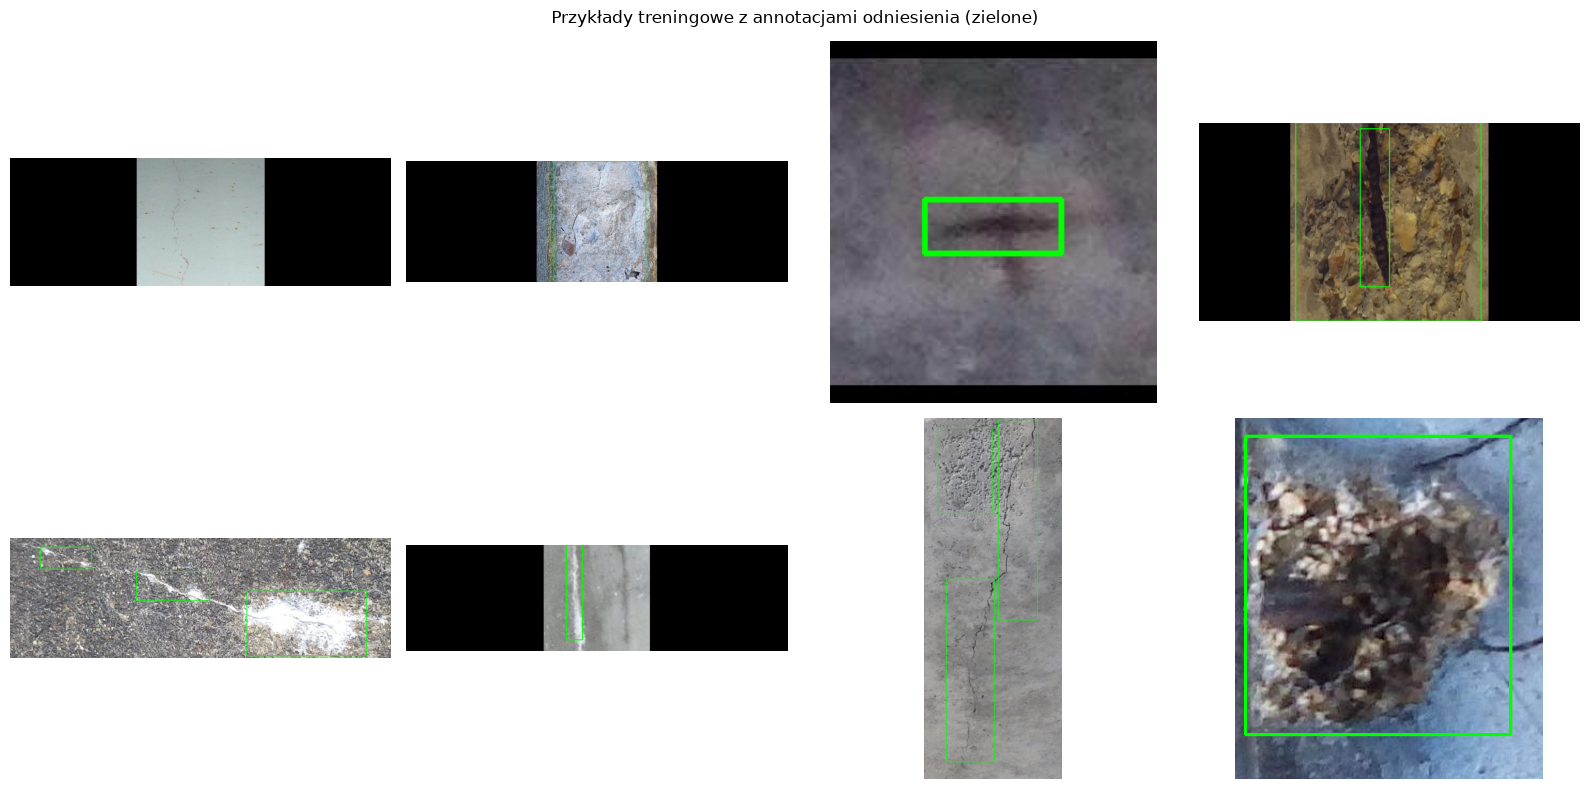

In [5]:
def draw_gt(path, thickness=2):
    im = cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)
    h, w = im.shape[:2]
    for c, v in read_label(label_of(path)):
        if len(v) == 4:
            cx, cy, bw, bh = v
            cv2.rectangle(im, (int((cx - bw / 2) * w), int((cy - bh / 2) * h)),
                              (int((cx + bw / 2) * w), int((cy + bh / 2) * h)), (0, 255, 0), thickness)
        else:
            pts = (np.array(v).reshape(-1, 2) * [w, h]).astype(np.int32)
            cv2.polylines(im, [pts], True, (0, 255, 0), thickness)
    return im

sample = random.Random(1).sample(train_imgs, 8)
fig, axs = plt.subplots(2, 4, figsize=(16, 8))
for ax, p in zip(axs.ravel(), sample):
    ax.imshow(draw_gt(p)); ax.axis("off")
plt.suptitle("Przykłady treningowe z annotacjami odniesienia (zielone)")
plt.tight_layout(); plt.savefig(RESULTS / "figures" / "dataset_examples.png", dpi=130); plt.show()

In [6]:
def source_key(p):
    return p.name.split(".rf.")[0]       # Nazewnictwo Roboflow: <source>_jpg.rf.<hash>.jpg

def pick(imgs, n, rng, dedup):
    if dedup:
        groups = {}
        for p in imgs:
            groups.setdefault(source_key(p), []).append(p)
        keys = sorted(groups); rng.shuffle(keys)
        imgs = [rng.choice(groups[k]) for k in keys]
    else:
        imgs = list(imgs); rng.shuffle(imgs)
    return imgs[:n]

def make_subset(sizes, out, dedup_train=True, seed=SEED):
    """Skopiuj ustalony losowy podzbiór do `out` (ten sam seed -> identyczny podzbiór dla każdego modelu)."""
    out = Path(out)
    if out.exists(): shutil.rmtree(out)
    for split, n in sizes.items():
        (out / split / "images").mkdir(parents=True); (out / split / "labels").mkdir(parents=True)
        for p in pick(list_images(split), n, random.Random(seed), dedup_train and split == "train"):
            shutil.copy(p, out / split / "images" / p.name)
            if label_of(p).exists():
                shutil.copy(label_of(p), out / split / "labels" / (p.stem + ".txt"))
    yaml.safe_dump({"path": str(out.resolve()), "train": "train/images", "val": "val/images", "test": "test/images",
                    "names": {i: n for i, n in enumerate(names)}}, open(out / "data.yaml", "w"))
    return out / "data.yaml"

SUB = WORK / "subset"
DATA_YAML = make_subset({"train": N_TRAIN, "val": N_VAL, "test": N_TEST}, SUB, DEDUP_TRAIN)
for s in ("train", "val", "test"):
    print(s, len(list((SUB / s / "images").iterdir())), "obrazów")
N_TRAIN_ACTUAL = len(list((SUB / "train" / "images").iterdir()))

train 1544 obrazów
val 400 obrazów
test 500 obrazów


## 2. Plan eksperymentu

**Wspólne ustawienia (Konfiguracja 1 i 2, wszystkie architektury):** seed 42, ten sam podzbiór i podział (train/val/test pochodzi z własnego podziału zbioru danych,
tak aby nie było przecieku między zbiorami), ten sam rozmiar wejściowy, ta sama liczba epok (bez early stopping), taka sama augmentacja (augmentacja online Ultralytics,
zdefiniowana poniżej w `AUG`), takie same metryki (precision, recall, mAP@0.5, mAP@0.5:0.95 na podzbiorze testowym, z wykorzystaniem punktu kontrolnego o najlepszym wyniku walidacyjnym).

**Hiperparametry dla każdej architektury (zgodnie z zadaniem):** dla wszystkich użyto optymalizatora AdamW. Learning rate 1e-3 dla małych modeli YOLO i 1e-4 dla RT-DETR
(detektory transformerowe zwykle wymagają niższego learning rate; jest to wartość zalecana w konfiguracji RT-DETR). Rozmiar batch jest taki sam dla wszystkich i zmniejszany automatycznie tylko przy braku pamięci GPU (zostanie to widoczne w kolumnie `batch`).

**Architektury:** dwa jednofazowe modele konwolucyjne z różnych generacji (YOLOv8n, YOLO11n) oraz detektor oparty na transformerze (RT-DETR-l).

**Konfiguracja 2 = jedna zmiana:** wagi z wstępnego treningu na COCO -> losowa inicjalizacja, taka sama liczba epok.

### Hipotezy (należy zapisać je PRZED treningami i zmienić teraz, jeśli nie są zgodne z oczekiwaniami, a nie dopiero po obejrzeniu wyników)

1. **Wstępne treningowanie pomaga każdej architekturze.** Przy krótkim treningu (15 epok, ~2000 obrazów) modele z wagami wstępnie wytrenowanymi osiągną wyraźnie większe mAP@0.5 na zbiorze testowym niż modele trenowane od podstaw, ponieważ niskopoziomowe filtry (krawędzie, tekstury) wyuczone na COCO przenoszą się na cienkie struktury pęknięć mimo różnicy obiektów.
2. **Wzrost zależy od architektury.** Największy powinien wystąpić dla RT-DETR-l: detektory transformerowe uczą się wolno i potrzebują wielu danych, więc trening od podstaw przez 15 epok powinien dawać wynik bliski zeru. Dla małych modeli YOLO opartych na CNN różnica będzie prawdopodobnie mniejsza, ponieważ filtrów konwolucyjnych dla krawędzi i tekstur można szybko nauczyć na obrazach pęknięć.
3. **Przy wagach wstępnie wytrenowanych** YOLOv8n i YOLO11n będą osiągać zbliżone wyniki (różnica kilku punktów mAP); RT-DETR-l może być porównywalny lub lekko lepszy pod względem mAP@0.5:0.95, ale będzie kilkukrotnie wolniejszy i cięższy.

In [7]:
from ultralytics import YOLO, RTDETR

SUFFIX = "-seg" if TASK == "segment" else ""
ARCHS = {
    "YOLOv8n":  dict(cls=YOLO, weights=f"yolov8n{SUFFIX}.pt", cfg=f"yolov8n{SUFFIX}.yaml", hp=dict(optimizer="AdamW", lr0=1e-3)),
    "YOLO11n":  dict(cls=YOLO, weights=f"yolo11n{SUFFIX}.pt", cfg=f"yolo11n{SUFFIX}.yaml", hp=dict(optimizer="AdamW", lr0=1e-3)),
}
if TASK == "detect":
    ARCHS["RT-DETR-l"] = dict(cls=RTDETR, weights="rtdetr-l.pt", cfg="rtdetr-l.yaml", hp=dict(optimizer="AdamW", lr0=1e-4))
else:
    # RT-DETR nie ma głowicy segmentacyjnej w Ultralytics, więc trzeci model to większy YOLOv8 (wspomnij o tym w prezentacji)
    ARCHS["YOLOv8s-seg"] = dict(cls=YOLO, weights="yolov8s-seg.pt", cfg="yolov8s-seg.yaml", hp=dict(optimizer="AdamW", lr0=1e-3))

AUG = dict(mosaic=1.0, close_mosaic=3, fliplr=0.5, flipud=0.0, degrees=0.0, translate=0.1, scale=0.5,
           hsv_h=0.015, hsv_s=0.7, hsv_v=0.4)
print("zadanie:", TASK, "| architektury:", list(ARCHS))

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\rzhiv\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
zadanie: detect | architektury: ['YOLOv8n', 'YOLO11n', 'RT-DETR-l']


## 3. Pomiar czasu na małej próbie (wymóg zadania)
Jedna epoch na 100 obrazach dla każdej architektury, ekstrapolowana na cały plan.

In [8]:
TIMING_YAML = make_subset({"train": 100, "val": 40, "test": 0}, WORK / "subset_timing", DEDUP_TRAIN)
timing = []
for arch, a in ARCHS.items():
    seed_all()
    model = a["cls"](a["weights"])
    t0 = time.time()
    model.train(data=str(TIMING_YAML), epochs=1, imgsz=IMGSZ, batch=BATCH, seed=SEED, workers=WORKERS,
                project=str(LOCAL_RUNS / "timing"), name=arch, exist_ok=True, verbose=False, plots=False, **AUG, **a["hp"])
    wall = time.time() - t0
    ep = getattr(model.trainer, "epoch_time", None) or wall
    per_epoch_full = ep * N_TRAIN_ACTUAL / 100
    timing.append(dict(arch=arch, sec_per_epoch_100img=round(ep, 1),
                       est_min_per_epoch_full=round(per_epoch_full / 60, 2),
                       est_min_both_configs=round(per_epoch_full * EPOCHS * 2 / 60, 1)))
    del model; gc.collect(); torch.cuda.empty_cache()
timing_df = pd.DataFrame(timing)
display(timing_df)
total = timing_df.est_min_both_configs.sum()
print(f"Szacowany całkowity czas treningu dla wszystkich 6 przebiegów: ~{total:.0f} min (~{total/60:.1f} h) + evaluation")
if total > 240:
    print("To zbyt długo dla darmowego Colab. Zmniejsz N_TRAIN / EPOCHS / IMGSZ w komórce ustawień i uruchom ponownie od tego miejsca.")
timing_df.to_csv(RESULTS / "timing_estimate.csv", index=False)

Ultralytics 8.4.215  Python-3.14.7 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 2060, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=3, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=work\subset_timing\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=YOLOv8n, nbs=64, nms=None, opset=None, optimize=Fal

c:\Users\rzhiv\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\autograd\graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


        1/1      4.94G      1.612      71.01      2.228          6        512: 100% ━━━━━━━━━━━━ 13/13 1.6s/it 20.5s0.8s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.3s/it 4.0s0.8s3s
                   all         40         93          0          0          0          0

1 epochs completed in 0.009 hours.
Optimizer stripped from G:\Studia\Przetwarzanie i analiza cyfrowych danych przestrzennych i budowlanych metodami sztucznej inteligencji\Projekt 4\runs\detect\work\runs\timing\RT-DETR-l\weights\last.pt, 66.2MB
Optimizer stripped from G:\Studia\Przetwarzanie i analiza cyfrowych danych przestrzennych i budowlanych metodami sztucznej inteligencji\Projekt 4\runs\detect\work\runs\timing\RT-DETR-l\weights\best.pt, 66.2MB

Validating G:\Studia\Przetwarzanie i analiza cyfrowych danych przestrzennych i budowlanych metodami sztucznej inteligencji\Projekt 4\runs\detect\work\runs\timing\RT-DETR-l\weights\best.pt...
Ultralytics 8

,arch,sec_per_epoch_100img,est_min_per_epoch_full,est_min_both_configs
0,YOLOv8n,9.4,2.41,72.2
1,YOLO11n,26.0,6.68,200.4
2,RT-DETR-l,32.6,8.39,251.7


Szacowany całkowity czas treningu dla wszystkich 6 przebiegów: ~524 min (~8.7 h) + evaluation
To zbyt długo dla darmowego Colab. Zmniejsz N_TRAIN / EPOCHS / IMGSZ w komórce ustawień i uruchom ponownie od tego miejsca.


## 4. Trening: 6 przebiegów
Każdy ukończony przebieg jest kopiowany do Google Drive wraz z plikiem metryk. Po rozłączeniu środowiska uruchom komórki ponownie; zakończone przebiegi zostaną pominięte.

In [9]:
def train_one(arch, pretrained, tag, batch):
    a = ARCHS[arch]
    seed_all()
    model = a["cls"](a["weights"] if pretrained else a["cfg"])   # .pt = wagi wstępnie wytrenowane, .yaml = losowa inicjalizacja
    model.train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=batch, seed=SEED, deterministic=True,
                workers=WORKERS, project=str(LOCAL_RUNS), name=tag, exist_ok=True, patience=EPOCHS + 5,
                verbose=False, plots=False, **AUG, **a["hp"])
    return model

def run_experiment(arch, pretrained):
    tag = f"{arch}_{'pretrained' if pretrained else 'scratch'}"
    final = RESULTS / "runs" / tag
    if (final / "metrics.json").exists():
        print("pominięto (zakończono wcześniej):", tag)
        return json.loads((final / "metrics.json").read_text())
    print("=" * 20, tag, "=" * 20)
    a, batch, t0 = ARCHS[arch], BATCH, time.time()
    while True:
        try:
            model = train_one(arch, pretrained, tag, batch); break
        except (torch.cuda.OutOfMemoryError, RuntimeError) as e:
            if "out of memory" not in str(e).lower() or batch <= 2: raise
            gc.collect(); torch.cuda.empty_cache(); batch //= 2
            print(f"Brak pamięci GPU -> ponowna próba z batch={batch}")
    train_min = (time.time() - t0) / 60
    save_dir = Path(model.trainer.save_dir)

    best = a["cls"](str(save_dir / "weights" / "best.pt"))
    m = best.val(data=str(DATA_YAML), split="test", imgsz=IMGSZ, batch=batch, plots=False, verbose=False,
                 project=str(LOCAL_RUNS), name=tag + "_test", exist_ok=True)
    mm = m.seg if TASK == "segment" else m.box
    p, r = float(mm.mp), float(mm.mr)
    params = sum(x.numel() for x in best.model.parameters()) / 1e6
    try:
        from ultralytics.utils.torch_utils import get_flops
        gflops = get_flops(best.model, IMGSZ)          # GFLOPs dla jednego obrazu IMGSZ × IMGSZ
    except Exception:
        gflops = float("nan")
    curve = pd.read_csv(save_dir / "results.csv"); curve.columns = [c.strip() for c in curve.columns]
    key = "metrics/mAP50(M)" if TASK == "segment" else "metrics/mAP50(B)"
    res = dict(run=tag, arch=arch, pretrained=pretrained, task=TASK, epochs=EPOCHS, imgsz=IMGSZ, batch=batch,
               train_min=round(train_min, 1), params_M=round(params, 1), gflops=round(float(gflops), 1),
               precision=p, recall=r, f1=2 * p * r / (p + r + 1e-9),
               mAP50=float(mm.map50), mAP50_95=float(mm.map), box_mAP50=float(m.box.map50),
               ms_per_img=float(m.speed["inference"]), best_val_mAP50=float(curve[key].max()),
               best_epoch=int(curve[key].idxmax()) + 1)
    final.mkdir(parents=True, exist_ok=True)
    shutil.copytree(save_dir, final, dirs_exist_ok=True)
    (final / "metrics.json").write_text(json.dumps(res, indent=1))
    del model, best; gc.collect(); torch.cuda.empty_cache()
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in res.items()})
    return res

failures = []
for pretrained in (True, False):          # Najpierw konfiguracja 1, potem konfiguracja 2
    for arch in ARCHS:
        try:
            run_experiment(arch, pretrained)
        except Exception as e:
            print("BŁĄD:", arch, pretrained, repr(e)); failures.append(f"{arch} pretrained={pretrained}: {e!r}")
            gc.collect(); torch.cuda.empty_cache()
if failures:
    (RESULTS / "failures.txt").write_text("\n".join(failures))
print("\nZakończono. Nieudane przebiegi:", failures or "none")

==================== YOLOv8n_pretrained ====================
Ultralytics 8.4.215  Python-3.14.7 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 2060, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=3, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=work\subset\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, n

c:\Users\rzhiv\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\autograd\graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/15      5.06G      1.137      2.532      1.074         41        512: 100% ━━━━━━━━━━━━ 193/193 1.1s/it 3:331.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 1.3s/it 33.4s0.2s
                   all        400        911    0.00105      0.157   0.000809   0.000198

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


c:\Users\rzhiv\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\autograd\graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       2/15      4.97G     0.7688       1.38     0.5781         29        512: 100% ━━━━━━━━━━━━ 193/193 1.2it/s 2:370.7ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 3.0it/s 8.4s0.3s
                   all        400        911    0.00216      0.238    0.00426     0.0015

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
       3/15      5.05G     0.7095      1.409     0.4878         34        512: 0% ──────────── 0/193  3.9s

c:\Users\rzhiv\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\autograd\graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (51 outputs left out)

c:\Users\rzhiv\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\autograd\graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      14/15      5.05G     0.9626     0.9779       1.26         18        512: 100% ━━━━━━━━━━━━ 193/193 1.6s/it 5:122.6ss7
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 2.4it/s 10.3s0.3s
                   all        400        911      0.207     0.0952     0.0233    0.00769

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
      15/15      5.05G      1.015     0.8499      1.314         16        512: 0% ──────────── 0/193  0.8s

c:\Users\rzhiv\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\autograd\graph.py:1072: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      15/15      5.05G     0.9318      1.017      1.172          8        512: 100% ━━━━━━━━━━━━ 193/193 1.2s/it 3:430.9ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 4.0it/s 6.2s0.2s
                   all        400        911      0.203      0.118     0.0258    0.00822

15 epochs completed in 0.794 hours.
Optimizer stripped from G:\Studia\Przetwarzanie i analiza cyfrowych danych przestrzennych i budowlanych metodami sztucznej inteligencji\Projekt 4\runs\detect\work\runs\RT-DETR-l_scratch\weights\last.pt, 66.2MB
Optimizer stripped from G:\Studia\Przetwarzanie i analiza cyfrowych danych przestrzennych i budowlanych metodami sztucznej inteligencji\Projekt 4\runs\detect\work\runs\RT-DETR-l_scratch\weights\best.pt, 66.2MB

Validating G:\Studia\Przetwarzanie i analiza cyfrowych danych przestrzennych i budowlanych metodami sztucznej inteligencji\Projekt 4\runs\detect\work\runs\RT-DETR-l_scratch\weights\best.pt...
Ultraly

## 5. Wyniki

,arch,config,precision,recall,f1,mAP50,mAP50_95,params_M,gflops,ms_per_img,train_min,batch,best_epoch
0,YOLOv8n,Konfiguracja 1: wstępne treningowanie,0.449,0.492,0.470,0.444,0.243,3.1,5.6,1.863,5.1,8,15
1,YOLO11n,Konfiguracja 1: wstępne treningowanie,0.475,0.426,0.449,0.420,0.228,2.6,4.2,1.938,5.6,8,15
2,RT-DETR-l,Konfiguracja 1: wstępne treningowanie,0.371,0.250,0.299,0.050,0.025,32.8,72.1,23.096,45.6,8,15
3,YOLOv8n,Konfiguracja 2: od podstaw,0.262,0.229,0.244,0.166,0.074,3.0,5.2,1.891,4.9,8,15
4,YOLO11n,Konfiguracja 2: od podstaw,0.348,0.196,0.251,0.126,0.055,2.6,4.1,1.940,5.3,8,15
5,RT-DETR-l,Konfiguracja 2: od podstaw,0.223,0.116,0.153,0.028,0.008,32.8,72.1,24.284,47.8,8,15


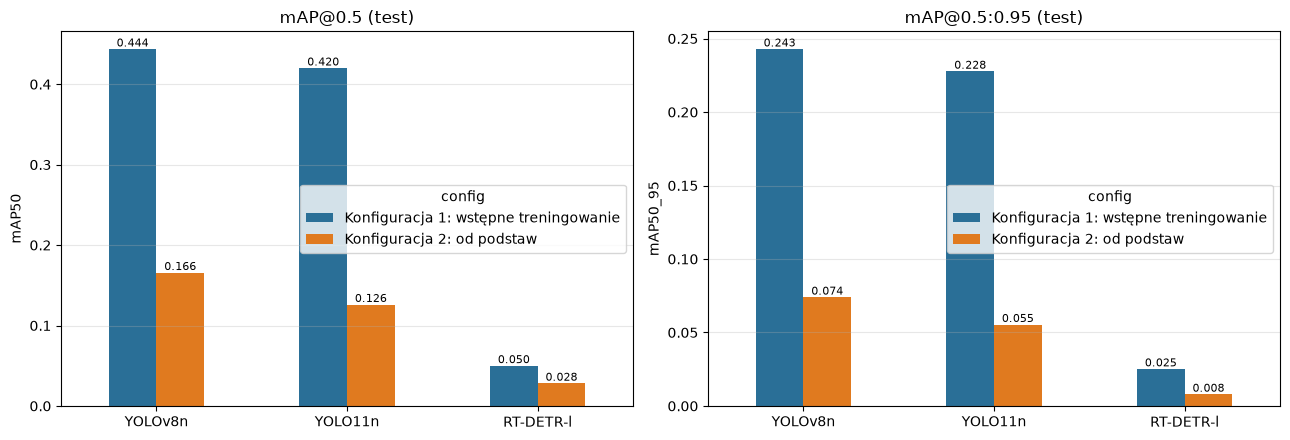

,wzrost mAP50 dzięki wstępnemu treningowi
arch,
YOLOv8n,0.278
YOLO11n,0.294
RT-DETR-l,0.022


In [10]:
df = pd.DataFrame([json.loads(p.read_text()) for p in sorted((RESULTS / "runs").glob("*/metrics.json"))])
df["config"] = np.where(df.pretrained, "Konfiguracja 1: wstępne treningowanie", "Konfiguracja 2: od podstaw")
order = [a for a in ARCHS if a in set(df.arch)]
df["arch"] = pd.Categorical(df.arch, order, ordered=True)
df = df.sort_values(["pretrained", "arch"], ascending=[False, True]).reset_index(drop=True)
cols = ["arch", "config", "precision", "recall", "f1", "mAP50", "mAP50_95", "params_M", "gflops", "ms_per_img", "train_min", "batch", "best_epoch"]
df[cols].round(3).to_csv(RESULTS / "results_summary.csv", index=False)
display(df[cols].round(3))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric, title in zip(axs, ["mAP50", "mAP50_95"], ["mAP@0.5 (test)", "mAP@0.5:0.95 (test)"]):
    pv = df.pivot(index="arch", columns="config", values=metric).reindex(order)
    pv.plot.bar(ax=ax, rot=0, color=["#2a6f97", "#e07a1f"])
    for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=8)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel(metric); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(RESULTS / "figures" / "comparison_map.png", dpi=140); plt.show()

pv = df.pivot(index="arch", columns="config", values="mAP50").reindex(order)
effect = (pv["Konfiguracja 1: wstępne treningowanie"] - pv["Konfiguracja 2: od podstaw"]).rename("wzrost mAP50 dzięki wstępnemu treningowi")
display(effect.round(3).to_frame())

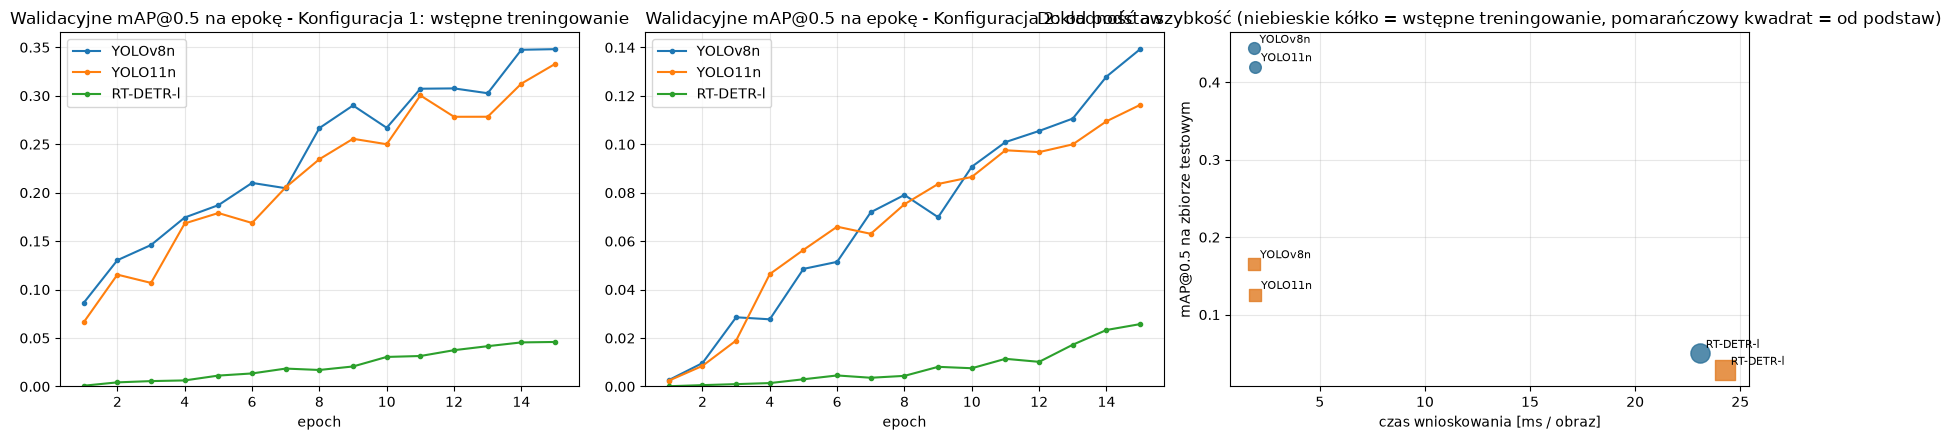

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
key = "metrics/mAP50(M)" if TASK == "segment" else "metrics/mAP50(B)"
for ax, (flag, title) in zip(axs[:2], [(True, "Konfiguracja 1: wstępne treningowanie"), (False, "Konfiguracja 2: od podstaw")]):
    for arch in order:
        f = RESULTS / "runs" / f"{arch}_{'pretrained' if flag else 'scratch'}" / "results.csv"
        if f.exists():
            c = pd.read_csv(f); c.columns = [x.strip() for x in c.columns]
            ax.plot(range(1, len(c) + 1), c[key], marker="o", ms=3, label=arch)
    ax.set_title(f"Walidacyjne mAP@0.5 na epokę - {title}"); ax.set_xlabel("epoch"); ax.set_ylim(bottom=0); ax.grid(alpha=.3); ax.legend()

for _, r in df.iterrows():
    axs[2].scatter(r.ms_per_img, r.mAP50, s=60 + 4 * r.params_M, marker="o" if r.pretrained else "s",
                   color="#2a6f97" if r.pretrained else "#e07a1f", alpha=.8)
    axs[2].annotate(r.arch, (r.ms_per_img, r.mAP50), fontsize=8, xytext=(4, 4), textcoords="offset points")
axs[2].set_xlabel("czas wnioskowania [ms / obraz]"); axs[2].set_ylabel("mAP@0.5 na zbiorze testowym")
axs[2].set_title("Dokładność a szybkość (niebieskie kółko = wstępne treningowanie, pomarańczowy kwadrat = od podstaw)"); axs[2].grid(alpha=.3)
plt.tight_layout(); plt.savefig(RESULTS / "figures" / "curves_and_speed.png", dpi=140); plt.show()

## 6. Przykładowe predykcje
Kolumny: etykieta odniesienia (zielona) i predykcja każdego modelu (conf >= 0.25). Pierwsze wiersze pokazują losowe obrazy testowe, a ostatnie — obrazy, na których najlepszy model popełnia najwięcej błędów (pominięte obiekty lub błędne detekcje przy IoU 0.3).

najgorsze obrazy (według oceny YOLOv8n ): ['018_3ovpa3qx-jey_jpg.rf.d8bebc', '015_t51g1k1c-cok_jpg.rf.30bb46', 'RIMG5214_w2nzg4io-13l_jpg.rf.7', 'O-11611_4_JPG_jpg.rf.13f6ea0c7']


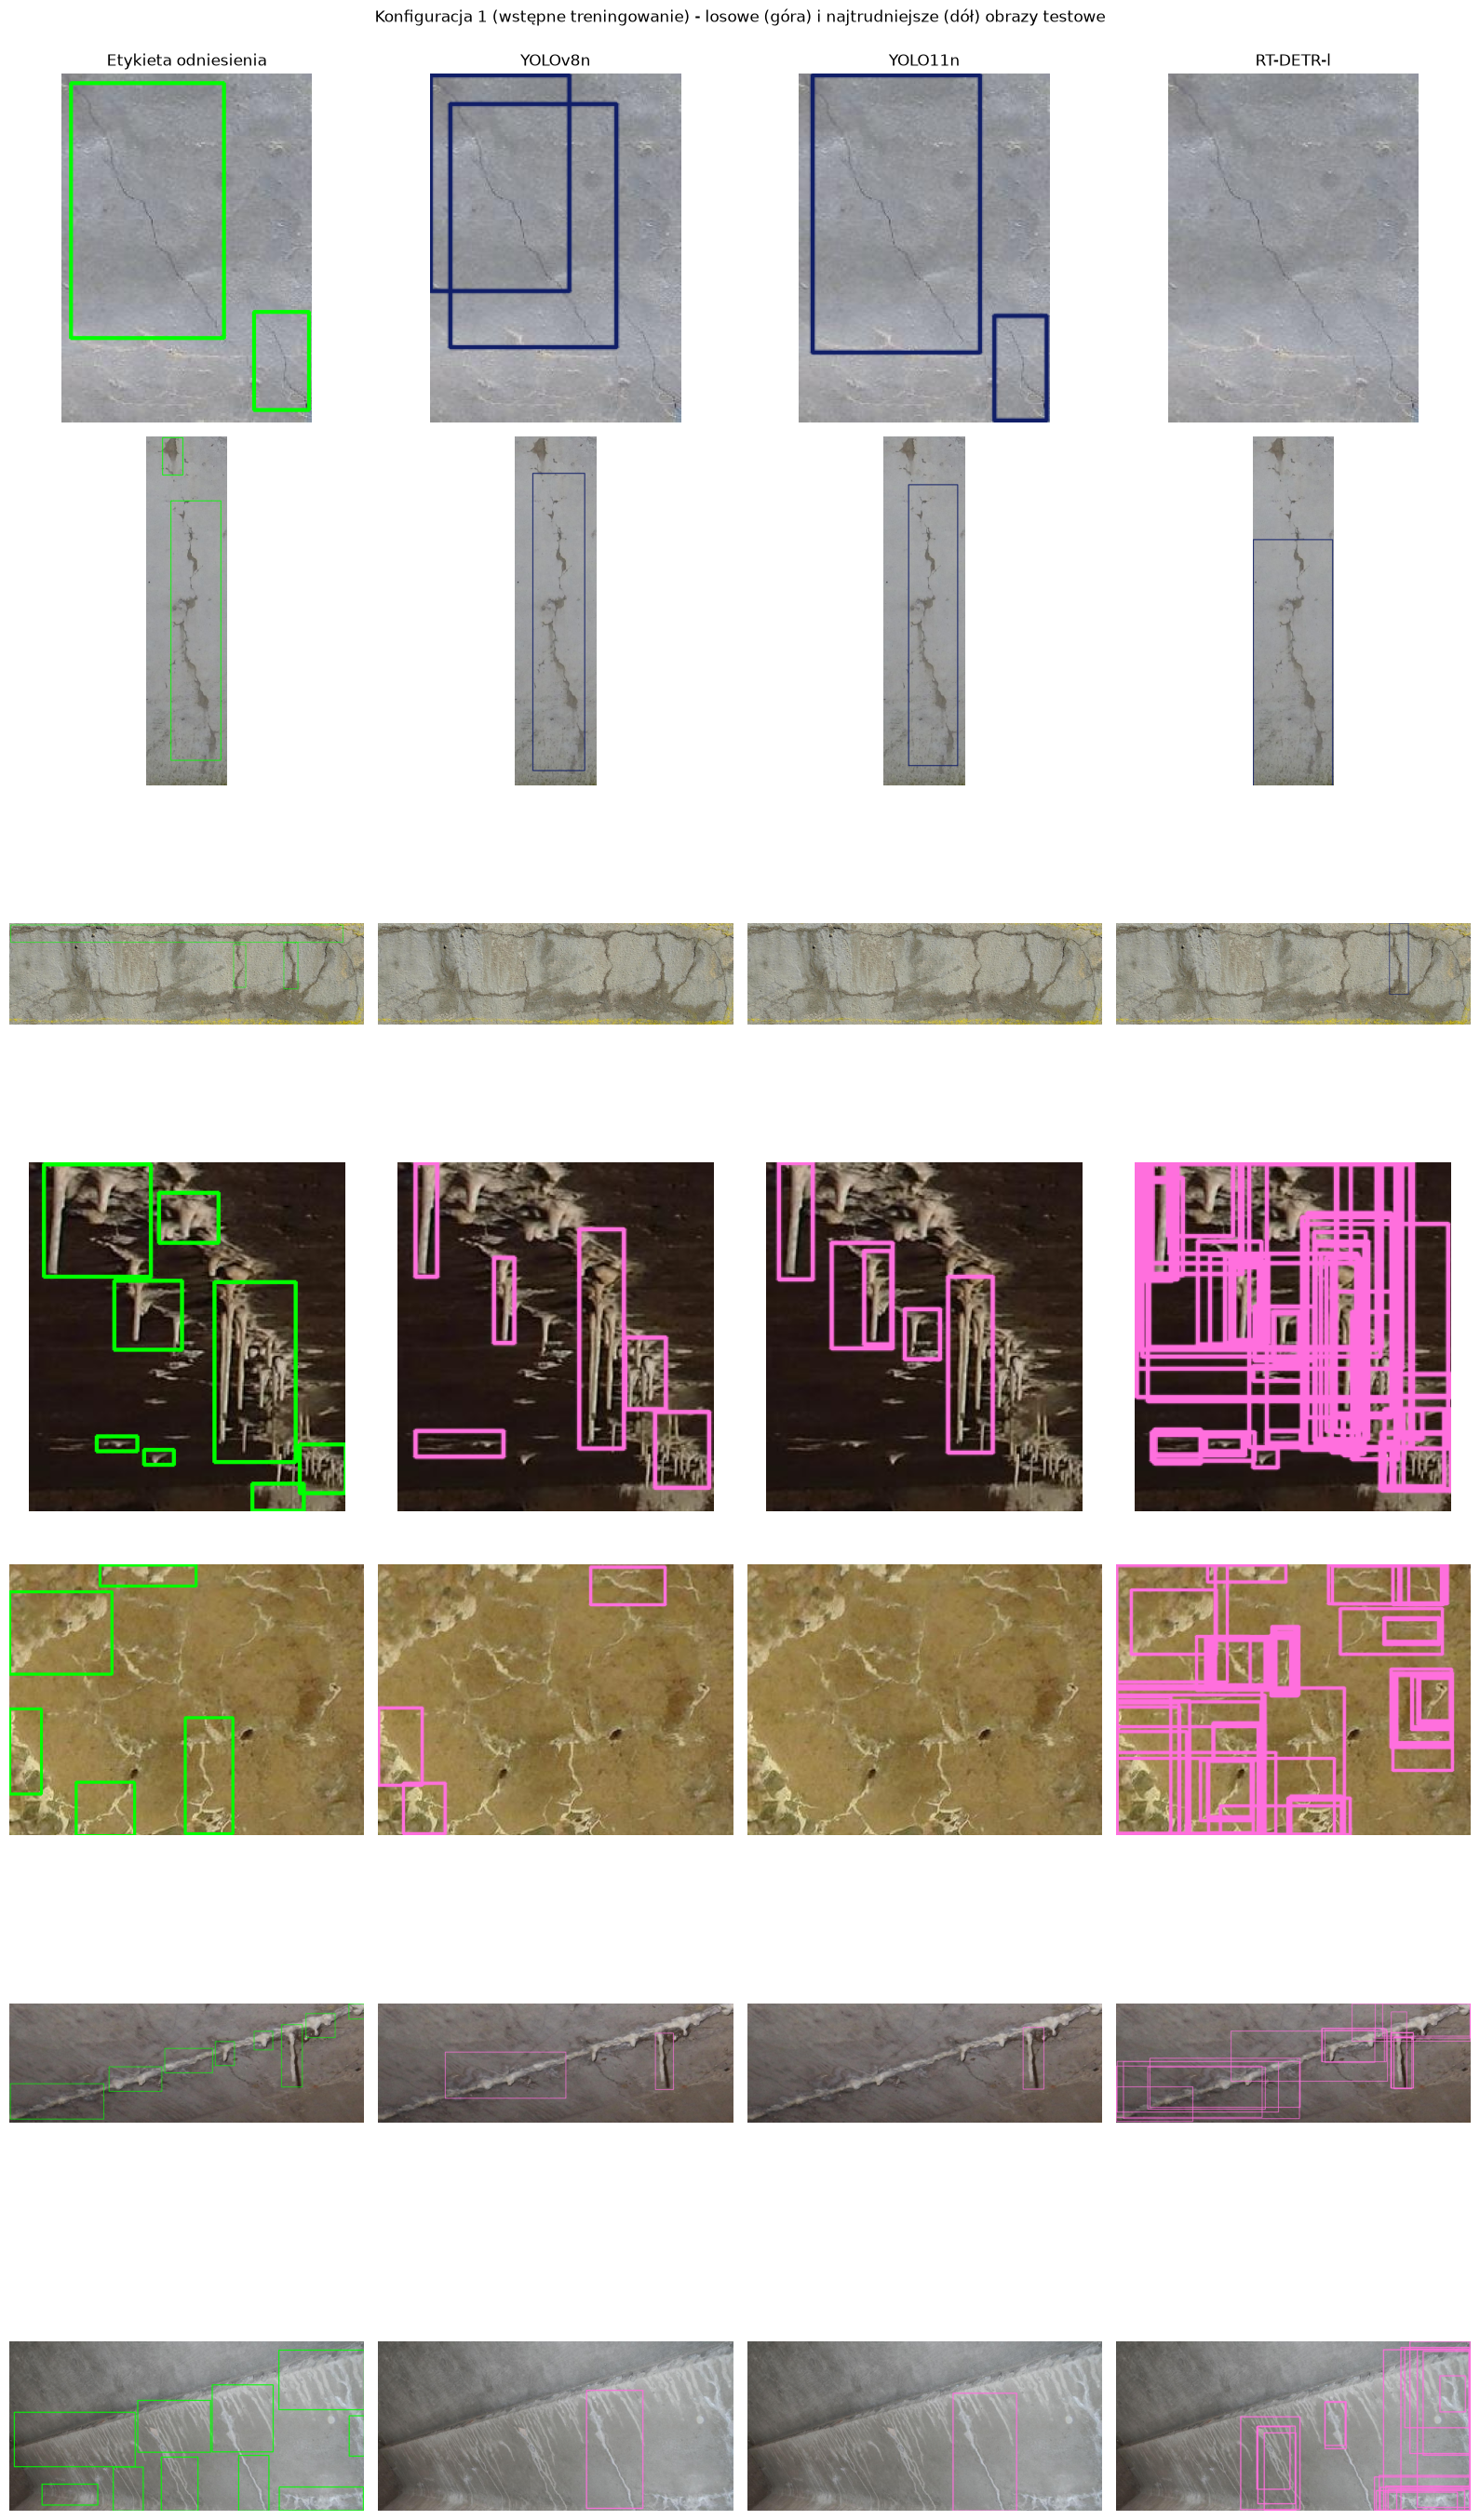

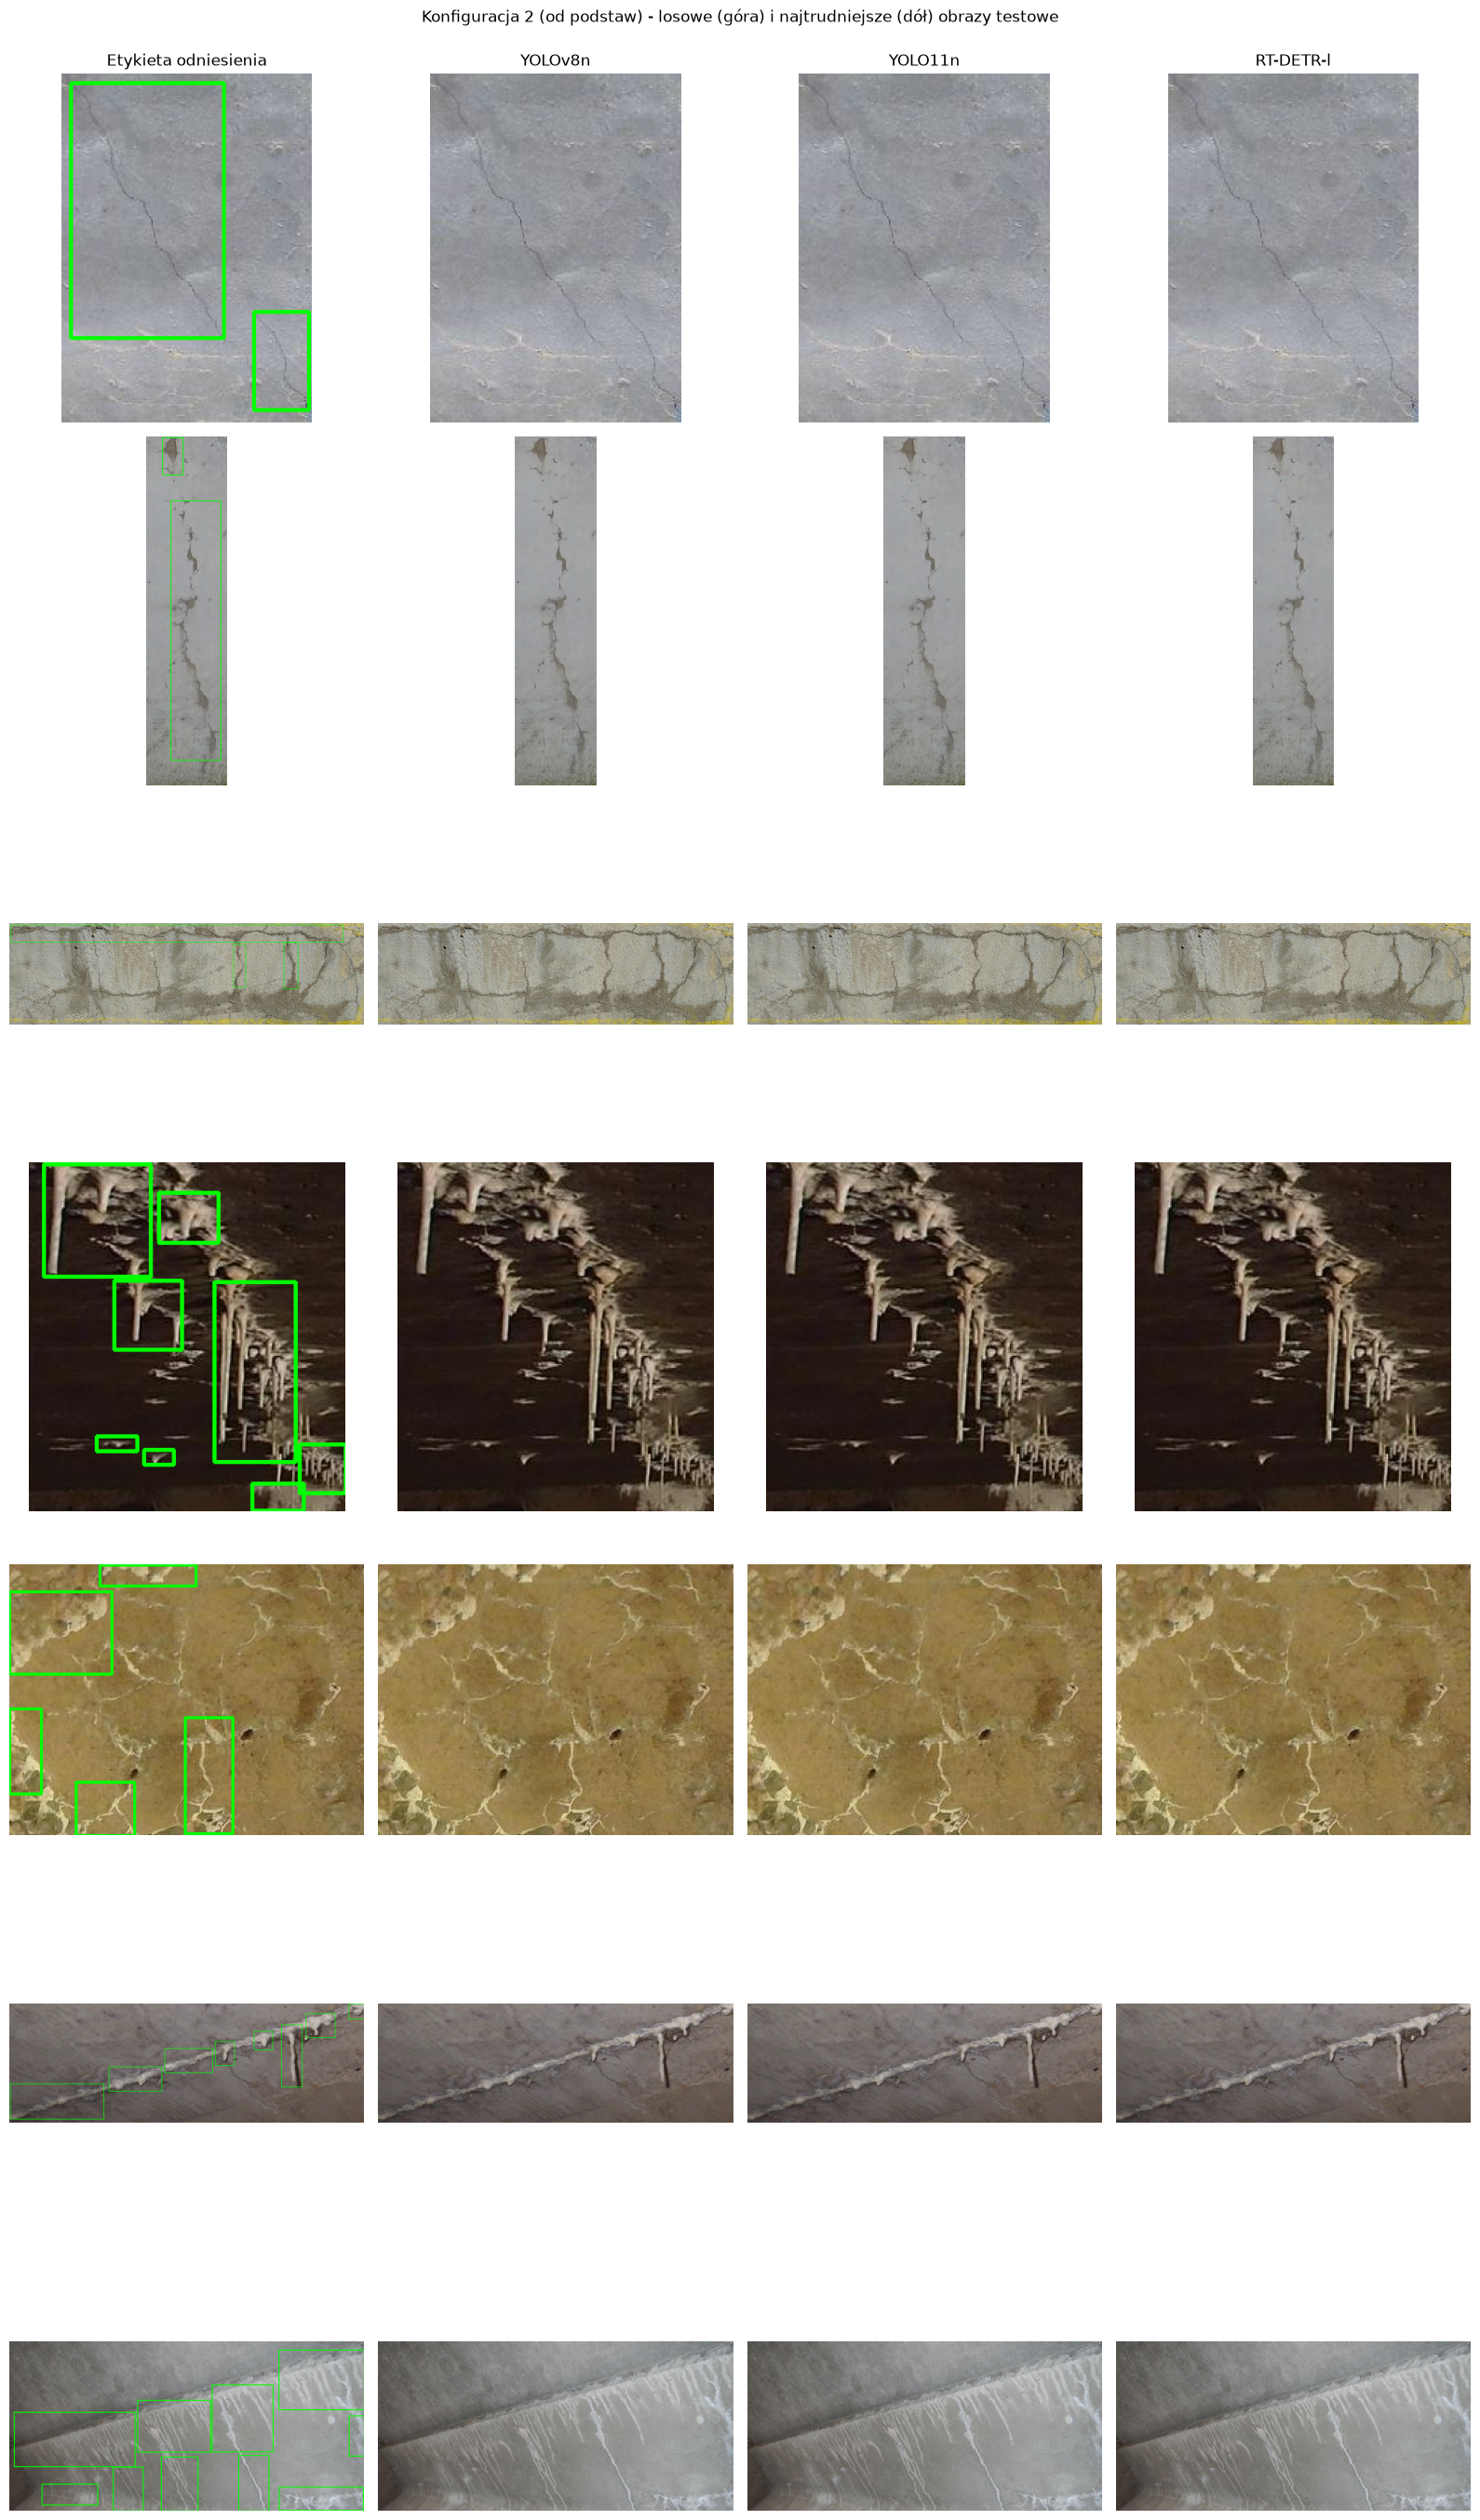

In [12]:
def load_best(arch, pretrained):
    tag = f"{arch}_{'pretrained' if pretrained else 'scratch'}"
    return ARCHS[arch]["cls"](str(RESULTS / "runs" / tag / "weights" / "best.pt"))

def gt_xyxy(path):
    h, w = cv2.imread(str(path)).shape[:2]
    out = []
    for _, v in read_label(label_of(path)):
        cx, cy, bw, bh = to_box_norm(v)
        out.append([(cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h])
    return np.array(out).reshape(-1, 4)

def iou(a, b):
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = lambda z: (z[:, 2] - z[:, 0]) * (z[:, 3] - z[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)

def count_errors(pred, gt, thr=0.3):
    if len(gt) == 0: return len(pred)
    if len(pred) == 0: return len(gt)
    m = iou(pred, gt); matched = 0
    while m.size and m.max() >= thr:
        i, j = np.unravel_index(m.argmax(), m.shape); matched += 1
        m[i, :] = -1; m[:, j] = -1
    return (len(pred) - matched) + (len(gt) - matched)

test_paths = sorted((SUB / "test" / "images").iterdir())
best_arch = df[df.pretrained].sort_values("mAP50", ascending=False).iloc[0].arch
ref = load_best(best_arch, True)
errs = []
for p, r in zip(test_paths, ref.predict([str(p) for p in test_paths], imgsz=IMGSZ, conf=0.25, verbose=False, stream=True)):
    errs.append(count_errors(r.boxes.xyxy.cpu().numpy(), gt_xyxy(p)))
worst = [test_paths[i] for i in np.argsort(errs)[::-1][:4]]
rng = random.Random(3)
rand = rng.sample([p for p in test_paths if p not in worst], 3)
print("najgorsze obrazy (według oceny", best_arch, "):", [p.name[:30] for p in worst])

def prediction_grid(paths, pretrained, fname):
    models = {a: load_best(a, pretrained) for a in order}
    fig, axs = plt.subplots(len(paths), 1 + len(models), figsize=(4 * (1 + len(models)), 4 * len(paths)))
    axs = np.atleast_2d(axs)
    for i, p in enumerate(paths):
        axs[i, 0].imshow(draw_gt(p)); axs[i, 0].set_title("Etykieta odniesienia" if i == 0 else "")
        for j, (a, m) in enumerate(models.items(), start=1):
            r = m.predict(str(p), imgsz=IMGSZ, conf=0.25, verbose=False)[0]
            axs[i, j].imshow(cv2.cvtColor(r.plot(conf=False, labels=False, line_width=2), cv2.COLOR_BGR2RGB))
            axs[i, j].set_title(a if i == 0 else "")
        for ax in axs[i]: ax.axis("off")
    plt.suptitle(("Konfiguracja 1 (wstępne treningowanie)" if pretrained else "Konfiguracja 2 (od podstaw)") + " - losowe (góra) i najtrudniejsze (dół) obrazy testowe", y=1.0)
    plt.tight_layout(); plt.savefig(RESULTS / "figures" / fname, dpi=120); plt.show()

prediction_grid(rand + worst, True, "predictions_config1_pretrained.png")
prediction_grid(rand + worst, False, "predictions_config2_scratch.png")

In [13]:
# Automatycznie wygenerowane dane do slajdów
b = df.sort_values("mAP50", ascending=False).iloc[0]
print(f"Najlepszy przebieg: {b.arch} / {b.config}  mAP50={b.mAP50:.3f}  mAP50-95={b.mAP50_95:.3f}  P={b.precision:.3f}  R={b.recall:.3f}")
for a in order:
    try:
        print(f"{a}: wstępne treningowanie {pv.loc[a, 'Konfiguracja 1: wstępne treningowanie']:.3f} vs od podstaw {pv.loc[a, 'Konfiguracja 2: od podstaw']:.3f}"
              f"  -> gain {effect[a]:+.3f}")
    except Exception: pass
print("Hipoteza 1 (wstępne treningowanie pomaga wszystkim):", "POTWIERDZONA" if (effect > 0).all() else "Niepotwierdzona dla: " + ", ".join(effect[effect <= 0].index))
if len(effect) == len(order) and order[-1] in effect.index:
    print(f"Hipoteza 2 (największy wzrost dla {order[-1]}):", "POTWIERDZONA" if effect.idxmax() == order[-1] else f"Niepotwierdzona, największy wzrost dla {effect.idxmax()}")

zip_path = RESULTS / "results_for_presentation.zip"
with zipfile.ZipFile(zip_path, "w") as z:
    for f in list((RESULTS / "figures").glob("*.png")) + list(RESULTS.glob("*.csv")):
        z.write(f, f.name)
print("Wykresy i tabele:", zip_path)
if IN_COLAB:
    from google.colab import files; files.download(str(zip_path))

Najlepszy przebieg: YOLOv8n / Konfiguracja 1: wstępne treningowanie  mAP50=0.444  mAP50-95=0.243  P=0.449  R=0.492
YOLOv8n: wstępne treningowanie 0.444 vs od podstaw 0.166  -> gain +0.278
YOLO11n: wstępne treningowanie 0.420 vs od podstaw 0.126  -> gain +0.294
RT-DETR-l: wstępne treningowanie 0.050 vs od podstaw 0.028  -> gain +0.022
Hipoteza 1 (wstępne treningowanie pomaga wszystkim): POTWIERDZONA
Hipoteza 2 (największy wzrost dla RT-DETR-l): Niepotwierdzona, największy wzrost dla YOLO11n
Wykresy i tabele: results\results_for_presentation.zip


## 7. Co umieścić na slajdach (powiązanie z wymaganiami zadania)
1. **Problem i zbiór danych:** detekcja pęknięć (lub segmentacja, patrz wynik `TASK` powyżej) na konstrukcjach betonowych, źródło: Roboflow Universe SHM v4 + licencja, liczba obrazów i klas z tabeli statystyk, `dataset_examples.png`.
2. **Plan eksperymentu:** tabela na początku tego notebooka, wspólne ustawienia, hiperparametry dla każdej architektury i ich uzasadnienie, Konfiguracja 2 = wstępne treningowanie vs trening od podstaw, trzy hipotezy.
3. **Porównanie:** `results_summary.csv`, `comparison_map.png`, `curves_and_speed.png`.
4. **Predykcje:** `predictions_config1_pretrained.png`, `predictions_config2_scratch.png` (dolne wiersze = błędy).
5. **Wnioski:** najlepsza architektura i konfiguracja, czy hipotezy zostały potwierdzone (wynik wypisano powyżej), co nie zadziałało i dlaczego, oraz dalsze kroki.

**Ograniczenia, o których warto uczciwie wspomnieć:** podzbiór danych, po jednym seedzie na przebieg (różnice rzędu 1–2 punktów mAP mogą być szumem), IoU jest wymagającą metryką dla bardzo cienkich pęknięć, Roboflow zastosował już odbicia i rotacje do obrazów treningowych, tylko jedno ustawienie hiperparametrów dla każdego modelu.